In [1]:
import os
print([f for f in os.listdir('.')])

['.cache', '.conda', '.condarc', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.python_history', '.vscode', 'AppData', 'Application Data', 'CNN_1.ipynb', 'CNN_1_GPU.ipynb', 'CNN_2_GPU.ipynb', 'CNN_2_GPU10ep.ipynb', 'ColorizationNet_best_100ep.pth', 'ColorizationNet_last_100ep.pth', 'colorization_epoch1.pth', 'color_net_best.pth', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{b907c333-eff3-11ee-9d8b-f80dacf2880d}.TM.blf', 'NTUSER.DAT{b907c333-eff3-11ee-9d8b-f80dacf2880d}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{b907c333-eff3-11ee-9d8b-f80dacf2880d}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Videos', 'XIA']


In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.current_device())
print(torch.cuda.get_device_name(0))

True
1
0
Quadro P600


In [3]:
# import cv2
# import numpy as np
# from skimage import io
# import os

# def convert_to_lab(image):
#     """Convert the input RGB image to Lab color space."""
#     lab_image = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
#     L_channel = lab_image[:,:,0]  # Lightness channel
#     ab_channels = lab_image[:,:,1:]  # A and B color channels
#     return L_channel, ab_channels

# def preprocess_image(image_path):
#     """Load the image."""
#     image = io.imread(image_path)
#     return image

# def save_grayscale_and_ab(input_image_path, output_l_path, output_ab_path):
#     """Process color images only, skip grayscale images."""
#     image = preprocess_image(input_image_path)

#     # Check if the image is grayscale (i.e., only 1 channel)
#     if len(image.shape) == 2 or (image.ndim == 3 and image.shape[2] == 1):
#         print(f"Skipped grayscale image: {input_image_path}")
#         return  # 直接跳过灰度图像

#     # Only process color images
#     L, ab = convert_to_lab(image)
#     L_uint8 = L.astype(np.uint8)
#     ab_int8 = ab.astype(np.int8)
#     np.save(output_l_path, L_uint8)
#     np.save(output_ab_path, ab_int8)
#     print(f"Processed and saved: {input_image_path}")

# def process_dataset(input_dir, output_dir):
#     """Process all color images in the directory, skip grayscale images."""
#     os.makedirs(output_dir, exist_ok=True)
#     image_files = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

#     for image_file in image_files:
#         image_path = os.path.join(input_dir, image_file)
#         output_l_path = os.path.join(output_dir, f"{image_file}_L.npy")
#         output_ab_path = os.path.join(output_dir, f"{image_file}_ab.npy")

#         save_grayscale_and_ab(image_path, output_l_path, output_ab_path)
#         # 不再需要 grey_only_directory 参数

# # Example usage:
# input_directory = r"C:\Users\Ting Ting\.cache\huggingface\hub\datasets--wangwangxuebing--train_COCO_data2014_jpg\snapshots\40294794d8e0a2bdc5683517173845f8d0ba6920"
# output_directory = r"C:\Users\Ting Ting\XIA\DATA\train2"

# process_dataset(input_directory, output_directory)


In [4]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
import torch.optim as optim
import torchvision
import random
from torch.utils.data import Dataset, DataLoader
import tqdm


In [5]:

data_dir = r"C:\Users\Ting Ting\XIA\DATA\train2"

# 1) 先把所有的 "_L.npy" 文件找出来，取出它们的前缀
all_L = [f for f in os.listdir(data_dir) if f.endswith("_L.npy")]
# e.g. "COCO_test2014_000000000057.jpg_L.npy" -> prefix="COCO_test2014_000000000057.jpg"
prefixes = [fname[:-6] for fname in all_L]

# 2) 随机打乱，然后按 70/30 划分
random.seed(42)
random.shuffle(prefixes)
n = len(prefixes)
n_train = int(0.7 * n)
train_prefixes = prefixes[:n_train]
val_prefixes   = prefixes[n_train:]

# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:

# import torch
# import torch.nn as nn
# import torch.nn.functional as F

# class ColorizationNet(nn.Module):
#     def __init__(self):
#         super().__init__()
#         # conv1 block
#         self.conv1_1 = nn.Conv2d(1, 64, 3, stride=1, padding=1)
#         self.bn1_1   = nn.BatchNorm2d(64)
#         self.conv1_2 = nn.Conv2d(64, 64, 3, 1, 1)
#         self.bn1_2   = nn.BatchNorm2d(64)

#         # conv2 block (downsample)
#         self.conv2_1 = nn.Conv2d(64,128,3,2,1)
#         self.bn2_1   = nn.BatchNorm2d(128)
#         self.conv2_2 = nn.Conv2d(128,128,3,1,1)
#         self.bn2_2   = nn.BatchNorm2d(128)

#         # conv3 block (downsample)
#         self.conv3_1 = nn.Conv2d(128,256,3,2,1)
#         self.bn3_1   = nn.BatchNorm2d(256)
#         self.conv3_2 = nn.Conv2d(256,256,3,1,1)
#         self.bn3_2   = nn.BatchNorm2d(256)
#         self.conv3_3 = nn.Conv2d(256,256,3,1,1)
#         self.bn3_3   = nn.BatchNorm2d(256)

#         # conv4 block (dilated)
#         self.conv4_1 = nn.Conv2d(256,512,3,1,2, dilation=2)
#         self.bn4_1   = nn.BatchNorm2d(512)
#         self.conv4_2 = nn.Conv2d(512,512,3,1,2, dilation=2)
#         self.bn4_2   = nn.BatchNorm2d(512)
#         self.conv4_3 = nn.Conv2d(512,512,3,1,2, dilation=2)
#         self.bn4_3   = nn.BatchNorm2d(512)

#         # conv5 block (more dilated)
#         self.conv5_1 = nn.Conv2d(512,512,3,1,2, dilation=2)
#         self.bn5_1   = nn.BatchNorm2d(512)
#         self.conv5_2 = nn.Conv2d(512,512,3,1,2, dilation=2)
#         self.bn5_2   = nn.BatchNorm2d(512)
#         self.conv5_3 = nn.Conv2d(512,512,3,1,2, dilation=2)
#         self.bn5_3   = nn.BatchNorm2d(512)

#         # 1x1 “classification” head
#         self.conv8_1 = nn.Conv2d(512,128,1)
#         self.bn8_1   = nn.BatchNorm2d(128)
#         self.conv8_2 = nn.Conv2d(128,313,1)  # 313 discrete color bins

#     def forward(self, L):
#         # L: (B,1,224,224), 内容是 Lab 中的 L 通道 - 50
#         def relu_bn(conv,bn,x):
#             return F.relu(bn(conv(x)), inplace=True)

#         x = relu_bn(self.conv1_1, self.bn1_1, L)
#         x = relu_bn(self.conv1_2, self.bn1_2, x)

#         x = relu_bn(self.conv2_1, self.bn2_1, x)
#         x = relu_bn(self.conv2_2, self.bn2_2, x)

#         x = relu_bn(self.conv3_1, self.bn3_1, x)
#         x = relu_bn(self.conv3_2, self.bn3_2, x)
#         x = relu_bn(self.conv3_3, self.bn3_3, x)

#         x = relu_bn(self.conv4_1, self.bn4_1, x)
#         x = relu_bn(self.conv4_2, self.bn4_2, x)
#         x = relu_bn(self.conv4_3, self.bn4_3, x)

#         x = relu_bn(self.conv5_1, self.bn5_1, x)
#         x = relu_bn(self.conv5_2, self.bn5_2, x)
#         x = relu_bn(self.conv5_3, self.bn5_3, x)

#         x = relu_bn(self.conv8_1, self.bn8_1, x)
#         logits = self.conv8_2(x)  # (B,313,H',W')
#         return logits


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ColorizationNet(nn.Module):
    def __init__(self, p_in=0.2):
        super().__init__()
        # ---------- Dropout 层 ----------
        # 输入噪声（可选）
        self.do_in   = nn.Dropout2d(p=p_in)
        # 分辨率 224 → 56 的卷积块里逐渐增大丢弃率
        self.do1 = nn.Dropout2d(0.25)
        self.do2 = nn.Dropout2d(0.35)
        self.do3 = nn.Dropout2d(0.40)
        self.do4 = nn.Dropout2d(0.50)
        self.do5 = nn.Dropout2d(0.50)      # bottleneck
        self.do_fc = nn.Dropout(0.50)      # 1×1 head

        # ---------- 卷积块与 BN ----------
        # conv1
        self.conv1_1 = nn.Conv2d(1, 64, 3, 1, 1)
        self.bn1_1   = nn.BatchNorm2d(64)
        self.conv1_2 = nn.Conv2d(64, 64, 3, 1, 1)
        self.bn1_2   = nn.BatchNorm2d(64)

        # conv2 (down)
        self.conv2_1 = nn.Conv2d(64,128,3,2,1)
        self.bn2_1   = nn.BatchNorm2d(128)
        self.conv2_2 = nn.Conv2d(128,128,3,1,1)
        self.bn2_2   = nn.BatchNorm2d(128)

        # conv3 (down)
        self.conv3_1 = nn.Conv2d(128,256,3,2,1)
        self.bn3_1   = nn.BatchNorm2d(256)
        self.conv3_2 = nn.Conv2d(256,256,3,1,1)
        self.bn3_2   = nn.BatchNorm2d(256)
        self.conv3_3 = nn.Conv2d(256,256,3,1,1)
        self.bn3_3   = nn.BatchNorm2d(256)

        # conv4 (dilated)
        self.conv4_1 = nn.Conv2d(256,512,3,1,2,dilation=2)
        self.bn4_1   = nn.BatchNorm2d(512)
        self.conv4_2 = nn.Conv2d(512,512,3,1,2,dilation=2)
        self.bn4_2   = nn.BatchNorm2d(512)
        self.conv4_3 = nn.Conv2d(512,512,3,1,2,dilation=2)
        self.bn4_3   = nn.BatchNorm2d(512)

        # conv5 (more dilated)
        self.conv5_1 = nn.Conv2d(512,512,3,1,2,dilation=2)
        self.bn5_1   = nn.BatchNorm2d(512)
        self.conv5_2 = nn.Conv2d(512,512,3,1,2,dilation=2)
        self.bn5_2   = nn.BatchNorm2d(512)
        self.conv5_3 = nn.Conv2d(512,512,3,1,2,dilation=2)
        self.bn5_3   = nn.BatchNorm2d(512)

        # 1×1 head
        self.conv8_1 = nn.Conv2d(512,64,1)
        self.bn8_1   = nn.BatchNorm2d(64)
        self.conv8_2 = nn.Conv2d(64,313,1)  # Q=313

    def _relu_bn(self, conv, bn, x):
        return F.relu(bn(conv(x)), inplace=True)

    def forward(self, L):            # L: (B,1,224,224)
        x = self.do_in(L)

        # conv1
        x = self._relu_bn(self.conv1_1, self.bn1_1, x)
        x = self._relu_bn(self.conv1_2, self.bn1_2, x)
        x = self.do1(x)

        # conv2
        x = self._relu_bn(self.conv2_1, self.bn2_1, x)
        x = self._relu_bn(self.conv2_2, self.bn2_2, x)
        x = self.do2(x)

        # conv3
        x = self._relu_bn(self.conv3_1, self.bn3_1, x)
        x = self._relu_bn(self.conv3_2, self.bn3_2, x)
        x = self._relu_bn(self.conv3_3, self.bn3_3, x)
        x = self.do3(x)

        # conv4
        x = self._relu_bn(self.conv4_1, self.bn4_1, x)
        x = self._relu_bn(self.conv4_2, self.bn4_2, x)
        x = self._relu_bn(self.conv4_3, self.bn4_3, x)
        x = self.do4(x)

        # conv5
        x = self._relu_bn(self.conv5_1, self.bn5_1, x)
        x = self._relu_bn(self.conv5_2, self.bn5_2, x)
        x = self._relu_bn(self.conv5_3, self.bn5_3, x)
        x = self.do5(x)

        # head
        x = self._relu_bn(self.conv8_1, self.bn8_1, x)
        x = self.do_fc(x)
        logits = self.conv8_2(x)             # (B,313,H',W')
        return logits


In [8]:
class TinyColorizationNet(nn.Module):
    def __init__(self):
        super().__init__()
        # conv1 block
        self.conv1_1 = nn.Conv2d(1, 16, 3, stride=1, padding=1)  # 更小通道
        self.bn1_1   = nn.BatchNorm2d(16)
        self.conv1_2 = nn.Conv2d(16, 16, 3, 1, 1)
        self.bn1_2   = nn.BatchNorm2d(16)

        # conv2 block (downsample)
        self.conv2_1 = nn.Conv2d(16, 32, 3, 2, 1)
        self.bn2_1   = nn.BatchNorm2d(32)
        self.conv2_2 = nn.Conv2d(32, 32, 3, 1, 1)
        self.bn2_2   = nn.BatchNorm2d(32)

        # conv3 block (downsample)
        self.conv3_1 = nn.Conv2d(32, 64, 3, 2, 1)
        self.bn3_1   = nn.BatchNorm2d(64)
        self.conv3_2 = nn.Conv2d(64, 64, 3, 1, 1)
        self.bn3_2   = nn.BatchNorm2d(64)

        # 1x1 “classification” head
        self.conv4_1 = nn.Conv2d(64, 32, 1)
        self.bn4_1   = nn.BatchNorm2d(32)
        self.conv4_2 = nn.Conv2d(32, 313, 1)  # 313 discrete color bins

    def forward(self, L):
        # L: (B,1,H,W)
        def relu_bn(conv, bn, x):
            return F.relu(bn(conv(x)), inplace=True)
        x = relu_bn(self.conv1_1, self.bn1_1, L)
        x = relu_bn(self.conv1_2, self.bn1_2, x)
        x = relu_bn(self.conv2_1, self.bn2_1, x)
        x = relu_bn(self.conv2_2, self.bn2_2, x)
        x = relu_bn(self.conv3_1, self.bn3_1, x)
        x = relu_bn(self.conv3_2, self.bn3_2, x)
        x = relu_bn(self.conv4_1, self.bn4_1, x)
        logits = self.conv4_2(x)  # (B,313,H',W')
        return logits

In [9]:
def ab2bin_idx(ab_img, ab_bins):
    # ab_img: (2, H, W) torch.float32
    # ab_bins: (313, 2) torch.float32
    H, W = ab_img.shape[1:]
    ab_flat = ab_img.reshape(2, -1).permute(1, 0)  # (H*W, 2)
    dists = torch.cdist(ab_flat, ab_bins)          # (H*W, 313)
    idxs = torch.argmin(dists, dim=1)              # (H*W,)
    return idxs.view(H, W)                         # (H, W)


In [10]:
def ab2bin_idx_batch(ab_tensor, ab_bins):
    """
    ab_tensor: (B,2,H,W)  float32
    ab_bins:   (313,2)    float32
    返回: (B,H,W) long
    """
    B, _, H, W = ab_tensor.shape
    # (B,2,H,W) -> (B,H*W,2)
    ab_flat = ab_tensor.permute(0,2,3,1).reshape(B, H*W, 2)  # (B,HW,2)
    # ab_bins: (313,2)

    # 距离：(B,HW,313) = (B,HW,2) - (1,1,313,2) = (B,HW,313,2)
    # 用广播做 (B,HW,2) => (B,HW,1,2), ab_bins(313,2) => (1,1,313,2)
    dists = ((ab_flat.unsqueeze(2) - ab_bins.unsqueeze(0).unsqueeze(0)) ** 2).sum(-1)  # (B,HW,313)

    # 取最小距离下标
    idxs = dists.argmin(-1)  # (B,HW)
    return idxs.view(B,H,W)


In [11]:
def ab2bin_soft_batch(ab_tensor, ab_bins, k=5, sigma=5.0):
    """
    Soft‐encode each (a,b) pixel into a Q‐dim distribution over the nearest k bins.

    Params
    ------
    ab_tensor : torch.Tensor, shape (B,2,H,W)
      原始 ab 通道张量
    ab_bins :   torch.Tensor, shape (Q,2)
      quantized ab 质心列表
    k :         int
      最近邻数量 (论文里用 5)
    sigma :    float
      Gaussian 核标准差 (论文里用 5)

    Returns
    -------
    soft_targets : torch.Tensor, shape (B, Q, H, W)
      每个像素在 Q 个 bin 上的 soft‐label 分布
    """
    B, _, H, W = ab_tensor.shape
    # 1) 平铺到 (B, N=H*W, 2)
    ab_flat = ab_tensor.permute(0,2,3,1).reshape(B, H*W, 2)
    # 2) 计算平方距离 (B, N, Q)
    #    ab_bins: (Q,2) -> (1,1,Q,2)
    diff = ab_flat.unsqueeze(2) - ab_bins.unsqueeze(0).unsqueeze(0)
    d2 = (diff**2).sum(-1)                   # (B, N, Q)
    # 3) 找 k 个最近邻
    d2_k, idx_k = d2.topk(k, dim=-1, largest=False)   # both (B, N, k)
    # 4) Gaussian 权重并归一化
    w = torch.exp(-d2_k / (2 * sigma**2))    # (B, N, k)
    w = w / (w.sum(dim=-1, keepdim=True) + 1e-12)
    # 5) scatter 到 soft‐target 张量
    soft = torch.zeros(B, H*W, ab_bins.size(0),
                       device=ab_tensor.device, dtype=ab_tensor.dtype)  # (B,N,Q)
    soft.scatter_(2, idx_k, w)              # 在 dim=2 上，把 k 个权重放进去
    # 6) reshape 回 (B, Q, H, W)
    soft = soft.permute(0,2,1).reshape(B, ab_bins.size(0), H, W)
    return soft


In [12]:
ab_bins = np.load(r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\pts_in_hull.npy")  # shape: (313, 2)
ab_bins = torch.from_numpy(ab_bins).float().to(device)  # (313,2)
Q = ab_bins.shape[0]  
ab_cpu = ab_bins.cpu().numpy() 

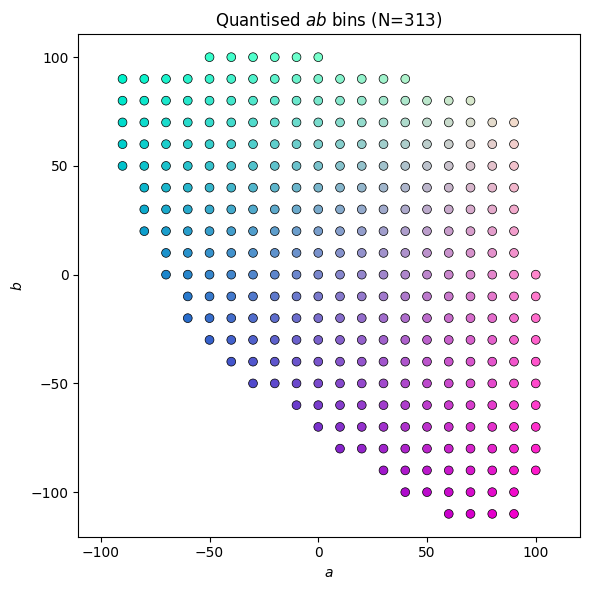

In [13]:

# ab_bins = np.load('pts_in_hull.npy')        # (313,2)
         # (313, 2)

# 2) 归一化到 [0,1] 做颜色映射（只是演示用）
ab_range = np.ptp(ab_cpu, axis=0)              # (2,)  =  max - min
ab_norm  = (ab_cpu - ab_cpu.min(0)) / (ab_range + 1e-8)

rgb = np.concatenate([ab_norm, np.full((ab_norm.shape[0], 1), 0.8)], axis=1)


# 3) 画散点图
plt.figure(figsize=(6,6))
plt.scatter(ab_cpu[:,0], ab_cpu[:,1],
            c=rgb, s=40, edgecolors='k', linewidths=.5)
plt.xlabel(r'$a$')
plt.ylabel(r'$b$')
plt.title('Quantised $ab$ bins (N=313)')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [14]:
# from torch.utils.data import Dataset, DataLoader

# class LABDataset(Dataset):
#     def __init__(self, data_dir):
#         self.data_dir = data_dir
#         self.fnames = [f for f in os.listdir(data_dir) if f.endswith('_L.npy')]

#     def __len__(self):
#         return len(self.fnames)

#     def __getitem__(self, idx):
#         l_path = os.path.join(self.data_dir, self.fnames[idx])
#         ab_path = l_path.replace("_L.npy", "_ab.npy")
#         L  = np.load(l_path).astype(np.float32)
#         ab = np.load(ab_path).astype(np.float32)
#         # mean-centering
#         L_input = L - 50.0
#         # to tensor
#         L_tensor = torch.from_numpy(L_input).unsqueeze(0) # (1,H,W)
#         ab_tensor = torch.from_numpy(ab).permute(2,0,1)   # (2,H,W)
#         return L_tensor, ab_tensor

# dataset = LABDataset(data_dir)
# dataloader = DataLoader(dataset, batch_size=4, shuffle=True)


In [15]:
# import time

# start = time.time()
# for i, (L_tensor, ab_tensor) in enumerate(dataloader):
#     if i % 100 == 0:
#         print(f"Loaded {i} batches")
#     if i == 500:  # 只测前500批，避免全程太久
#         break
# end = time.time()
# print(f"读取500个batch（共{500*4}张图）耗时: {end-start:.2f} 秒")


In [16]:
# for epoch in range(num_epochs):
#     net.train()
#     running_loss = 0.0

#     for L_tensor, ab_tensor in dataloader:  # L_tensor: (B,1,H,W); ab_tensor: (B,2,H,W)
#         # 放到 device
#         L_tensor = L_tensor.to(device)
#         ab_tensor = ab_tensor.to(device)
        
#         # ab_tensor: (B,2,H,W) -> target: (B,H,W)，对 batch 每个样本做ab2bin_idx
#         with torch.no_grad():
#             # 用 list comprehension 处理 batch
#             target = torch.stack([
#                 ab2bin_idx(ab_tensor[i], ab_bins) for i in range(ab_tensor.shape[0])
#             ]).to(device)  # (B,H,W)
        
#         optimizer.zero_grad()
#         logits = net(L_tensor)   # (B,313,h,w)
#         logits_up = F.interpolate(logits, size=target.shape[1:], mode="bilinear", align_corners=False)
#         loss = criterion(logits_up, target)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * L_tensor.size(0)  # batch loss求和

#     print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(dataset):.4f}")
#     torch.save(net.state_dict(), f'colorization_epoch{epoch+1}.pth')


In [17]:
# for epoch in range(num_epochs):
#     net.train()
#     running_loss = 0.0

#     for fname in os.listdir(data_dir):
#         if not fname.endswith("_L.npy"):
#             continue

#         l_path  = os.path.join(data_dir, fname)
#         ab_path = l_path.replace("_L.npy", "_ab.npy")

#         # 1) 加载数据
#         # L  = np.load(l_path)   # (H, W)
#         # ab = np.load(ab_path)  # (H, W, 2)
#         L  = np.load(l_path).astype(np.float32)
#         ab = np.load(ab_path).astype(np.float32)

#         # 2) mean-centering
#         L_input = L.astype(np.float32) - 50.0

#         # 3) 转成tensor
#         L_tensor  = torch.from_numpy(L_input).unsqueeze(0).unsqueeze(0).to(device)      # (1,1,H,W)
#         ab_tensor = torch.from_numpy(ab.astype(np.float32)).permute(2,0,1).unsqueeze(0).to(device) # (1,2,H,W)

#         # 4) 量化ab为分类标签
#         # target = ab2bin_idx(ab_tensor[0], ab_bins).unsqueeze(0).to(device)  # (1,H,W)
#         with torch.no_grad():
#             target = ab2bin_idx_batch(ab_tensor, ab_bins)  # (B,H,W)

#         # 5) 前向+反向
#         optimizer.zero_grad()
#         logits = net(L_tensor)   # (1,313,h,w)
#         logits_up = F.interpolate(logits, size=target.shape[1:], mode="bilinear", align_corners=False)
#         loss = criterion(logits_up, target)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()

#     print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss:.4f}")
#     torch.save(net.state_dict(), f'colorization_epoch{epoch+1}.pth')


In [18]:
# 3) 定义一个 Dataset，从这些前缀里分别加载 L 和 ab
class PairDataset(Dataset):
    def __init__(self, prefixes, data_dir, out_size):
        self.prefixes = prefixes
        self.data_dir  = data_dir
        self.out_h, self.out_w = out_size

    def __len__(self):
        return len(self.prefixes)

    def __getitem__(self, idx):
        prefix = self.prefixes[idx]
        L_path  = os.path.join(self.data_dir, prefix + "_L.npy")
        ab_path = os.path.join(self.data_dir, prefix + "_ab.npy")
        L  = np.load(L_path).astype(np.float32)      # (H,W)
        ab = np.load(ab_path).astype(np.float32)     # (H,W,2)
        L_input = L - 50.0
        # —— 在这里做 resize ——  
        # 先把 numpy 转成 torch Tensor，再用 interpolate
        L_tensor  = torch.from_numpy(L_input[None,None]).float()      # (1,1,H,W)
        ab_tensor = torch.from_numpy(ab).permute(2,0,1).unsqueeze(0).float()  # (1,2,H,W)

        L_tensor  = F.interpolate(L_tensor,  size=(self.out_h, self.out_w), mode='bilinear', align_corners=False).squeeze(0)
        ab_tensor = F.interpolate(ab_tensor, size=(self.out_h, self.out_w), mode='bilinear', align_corners=False).squeeze(0)

        return L_tensor, ab_tensor


In [19]:
        # l_path = os.path.join(self.data_dir, self.fnames[idx])
        # ab_path = l_path.replace("_L.npy", "_ab.npy")
        # L  = np.load(l_path).astype(np.float32)
        # ab = np.load(ab_path).astype(np.float32)
        # # mean-centering
        # L_input = L - 50.0
        # # to tensor
        # L_tensor = torch.from_numpy(L_input).unsqueeze(0) # (1,H,W)
        # ab_tensor = torch.from_numpy(ab).permute(2,0,1)   # (2,H,W)

In [20]:

# 4) 用它们创建 train/val Dataset 和 DataLoader
size=(64, 64)  # rezise to size
traindataset = PairDataset(train_prefixes, data_dir, out_size=size)
valdataset   = PairDataset(val_prefixes,   data_dir, out_size=size)

trainloader = DataLoader(traindataset, batch_size=32, shuffle=True,  num_workers=0)
valloader   = DataLoader(valdataset,   batch_size=32, shuffle=False, num_workers=0)

In [21]:
from scipy.ndimage import gaussian_filter1d

counts = torch.zeros(Q, dtype=torch.float64)
print("Computing global bin histogram...")
for L_tensor, ab_tensor in tqdm.tqdm(trainloader):
    # ab_tensor: (B,2,H,W)
    idxs = ab2bin_idx_batch(ab_tensor.to(device), ab_bins)  # (B,H,W)
    flat = idxs.view(-1).cpu()                             # 拉平到一维
    counts += torch.bincount(flat, minlength=Q).double()

# —— 3) 平滑 + 混合 + 倒数 + 归一化 —— 
p = counts / counts.sum()                                # 经验分布 p_q
p_smooth = torch.from_numpy(gaussian_filter1d(p.numpy(), sigma=5))
λ = 0.5
p_hat = (1 - λ) * p_smooth + λ / Q
w = 1.0 / p_hat                                         # 取倒数
w = w / (p * w).sum()                                   # 归一化 E_p[w]=1
class_weights = w.float().to(device)                    # 最终的 (313,) 向量

print("class_weights ready:", class_weights.shape)

Computing global bin histogram...


100%|██████████| 217/217 [03:15<00:00,  1.11it/s]

class_weights ready: torch.Size([313])


In [22]:
def soft_weighted_ce(logits, soft_targets, weight_map):
    """
    logits:       (B, Q, H, W)   raw scores
    soft_targets: (B, Q, H, W)   软标签分布 Z_{h,w,q}
    weight_map:   (B,   H, W)    每像素标量 v(h,w)
    """
    # 1) 先算 log‐prob
    log_p = F.log_softmax(logits, dim=1)      # (B,Q,H,W)
    # 2) 把 weight_map 扩成 (B,1,H,W) 以便广播
    v = weight_map.unsqueeze(1)               # (B,1,H,W)
    # 3) 带权重的 soft‐CE
    #    loss_map[b,q,h,w] = - v[b,1,h,w] * soft_targets[b,q,h,w] * log_p[b,q,h,w]
    loss_map = - v * soft_targets * log_p     # (B,Q,H,W)
    # 4) 先对 q 求和，再对 B×H×W 求 mean
    return loss_map.sum(dim=1).mean()


In [25]:
def apply_max_norm(model, c=4.0):
    # 在 no_grad 里所有原地操作就不会被 Autograd 跟踪
    with torch.no_grad():
        for name, w in model.named_parameters():
            if w.dim() > 1 and 'weight' in name:
                # 计算每一列的 L2 范数
                norm = w.norm(2, dim=0, keepdim=True)
                # 限制在 [0, c]
                desired = torch.clamp(norm, max=c)
                # 原地缩放（这里不会被 Autograd 记录）
                w.mul_(desired / (norm + 1e-8))

In [ ]:
#loss is probbility of pixel in the each idx  
# 5. 初始化模型
import tqdm
ckpt_dir    = r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\model"
net = TinyColorizationNet().to(device)
# optimizer = torch.optim.SGD(
#     model.parameters(),
#     lr=1e-2,          # 提升 10 倍起步
#     momentum=0.97,    # 更高动量
#     weight_decay=0    # L2 可先关掉，交由 Max-Norm + Dropout
# )
optimizer = torch.optim.Adam(net.parameters(), lr=3e-4, weight_decay=0.0 )
# criterion = torch.nn.CrossEntropyLoss(ignore_index=313)
num_epochs = 50
best_val_acc = 0

model_name = net.__class__.__name__ 
best_ckpt = os.path.join(ckpt_dir, f"{model_name}_best_{num_epochs}ep.pth")
last_ckpt = os.path.join(ckpt_dir, f"{model_name}_last_{num_epochs}ep.pth")

tr_accuracies = np.zeros(num_epochs)
val_accuracies = np.zeros(num_epochs)
tr_losses = np.zeros(num_epochs)
val_losses = np.zeros(num_epochs)

start_time = time.time()

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    running_acc = 0.0
    total_pixel = 0

    for L_tensor, ab_tensor in tqdm.tqdm(trainloader):
        L_tensor = L_tensor.to(device)         # (B,1,H,W)
        ab_tensor = ab_tensor.to(device)# (B,2,H,W)
        # —— 1) 计算 soft‐targets 和 每像素 weight_map ——
        with torch.no_grad():
            # soft_targets: (B,Q,H,W)
            soft_targets = ab2bin_soft_batch(ab_tensor, ab_bins).to(device)
            # 找到最可能的 bin，用于 accuracy 以及索引权重
            hard_idx   = soft_targets.argmax(dim=1)          # (B,H,W)
            # weight_map: (B,H,W)
            weight_map = class_weights[hard_idx]             # 根据索引取权重向量

        # —— 2) 前向 + loss ——
        optimizer.zero_grad()
        logits = net(L_tensor)                               # (B,Q,H',W')
        # 上采样到和 soft_targets 相同大小
        logits_up = F.interpolate(logits,
                                size=soft_targets.shape[2:],
                                mode="bilinear",
                                align_corners=False)
        # 用自定义的 soft_weighted_ce
        loss = soft_weighted_ce(logits_up, soft_targets, weight_map)
        loss.backward()
        optimizer.step()
        apply_max_norm(net, c=4.0)                     # ⑥


        running_loss += loss.item() * L_tensor.size(0)
        preds = logits_up.argmax(1)
        correct = (preds == hard_idx).float().sum().item()
        total = torch.numel(hard_idx)
        # print("batch total:", total)
        running_acc += correct
        total_pixel += total
        

    tr_loss = running_loss / len(traindataset)
    tr_acc = 100 * running_acc / total_pixel
    tr_accuracies[epoch] = tr_acc
    tr_losses[epoch] = tr_loss
    

    print(f">> TRAIN: Epoch {epoch} | tr_loss: {tr_loss:.4f} | tr_acc: {tr_acc:.2f}%")


    # ----------------- Validation -----------------
    net.eval()
    val_running_loss = 0.0
    val_running_acc  = 0.0
    val_total_pixel  = 0

    with torch.no_grad():
        for L_tensor, ab_tensor in tqdm.tqdm(valloader):
            L_tensor = L_tensor.to(device)   # (B,1,H,W)
            ab_tensor= ab_tensor.to(device)  # (B,2,H,W)

            # 1) 准备 soft_targets 和 weight_map
            soft_targets = ab2bin_soft_batch(ab_tensor, ab_bins)      # (B,Q,H,W)
            hard_idx      = soft_targets.argmax(dim=1)               # (B,H,W)
            weight_map    = class_weights[hard_idx]                  # (B,H,W)

            # 2) forward + loss
            logits    = net(L_tensor)                                # (B,Q,h',w')
            logits_up = F.interpolate(
                logits,
                size=soft_targets.shape[2:], 
                mode="bilinear", 
                align_corners=False
            )                                                        # (B,Q,H,W)
            loss = soft_weighted_ce(logits_up, soft_targets, weight_map)
            val_running_loss += loss.item() * L_tensor.size(0)

            # 3) accuracy
            preds = logits_up.argmax(dim=1)                          # (B,H,W)
            val_running_acc += (preds == hard_idx).sum().item()
            val_total_pixel += hard_idx.numel()

    # 4) 汇总
    val_loss = val_running_loss / len(valdataset)
    val_acc  = 100 * val_running_acc / val_total_pixel
    val_accuracies[epoch] = val_acc
    val_losses[epoch] = val_loss
    print(f">> VALIDATION: val_loss: {val_loss:.4f} | val_acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(net.state_dict(), best_ckpt)
        print(f">> SAVE: Epoch {epoch} | Model saved")

end_time = time.time()
print('Finished Training in {:.2f} seconds'.format(end_time-start_time))
torch.save(net.state_dict(), last_ckpt)
#the speed is really slow if i use resize(112*112), so i use orignal size(32*32)

  0%|          | 0/217 [00:00<?, ?it/s]

100%|██████████| 217/217 [01:58<00:00,  1.84it/s]


>> TRAIN: Epoch 0 | tr_loss: 1.9567 | tr_acc: 5.45%


100%|██████████| 93/93 [01:42<00:00,  1.11s/it]


>> VALIDATION: val_loss: 1.7464 | val_acc: 6.09%
>> SAVE: Epoch 0 | Model saved


100%|██████████| 217/217 [02:03<00:00,  1.76it/s]


>> TRAIN: Epoch 1 | tr_loss: 1.6221 | tr_acc: 7.07%


100%|██████████| 93/93 [00:43<00:00,  2.15it/s]

>> VALIDATION: val_loss: 1.5203 | val_acc: 8.50%
>> SAVE: Epoch 1 | Model saved
Finished Training in 387.89 seconds


In [27]:
# import os, shutil, torch
# ckpt_dir    = r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\model"
# os.makedirs(ckpt_dir, exist_ok=True)

# # 已经在当前工作目录里的旧文件名
# old_best = f"{model_name}_best_{num_epochs}ep.pth"
# old_last = f"{model_name}_last_{num_epochs}ep.pth"

# # 拟保存的新绝对路径
# new_best = os.path.join(ckpt_dir, f"{model_name}_T_best_{num_epochs}ep.pth")
# new_last = os.path.join(ckpt_dir, f"{model_name}_T_last_{num_epochs}ep.pth")

# # -------------------------------------------------
# # 2) 定义一个“小助手”做复制 / 覆盖提示
# # -------------------------------------------------
# def move_or_copy(src, dst, *, move=True):
#     if not os.path.isfile(src):
#         print(f"[WARN] 源文件不存在: {src}")
#         return
#     if os.path.isfile(dst):
#         print(f"[INFO] 目标已存在，将被覆盖: {dst}")
#         os.remove(dst)
#     shutil.move(src, dst) if move else shutil.copy2(src, dst)
#     print(f"[OK]  {src}  ->  {dst}")

# # -------------------------------------------------
# # 3) 执行
# # -------------------------------------------------
# move_or_copy(old_best, new_best, move=False)  # False 表示“复制”；想“移动”就改 True
# move_or_copy(old_last, new_last, move=False)

# print("\nDone. 你可以在文件资源管理器中查看：")
# print(f"  {new_best}")
# print(f"  {new_last}")

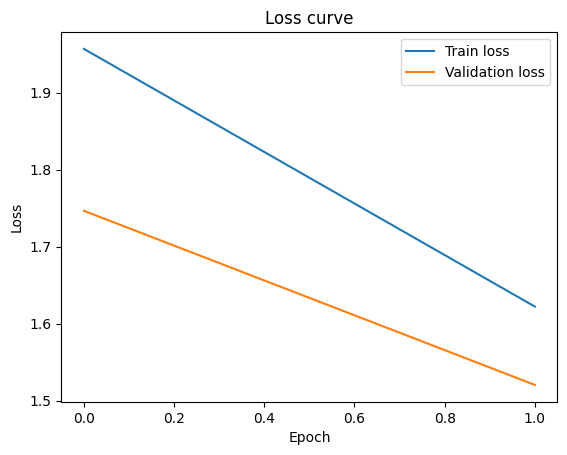

In [28]:
plt.figure()
plt.plot(tr_losses, label='Train loss')
plt.plot(val_losses, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curve')
plt.legend()
plt.show()

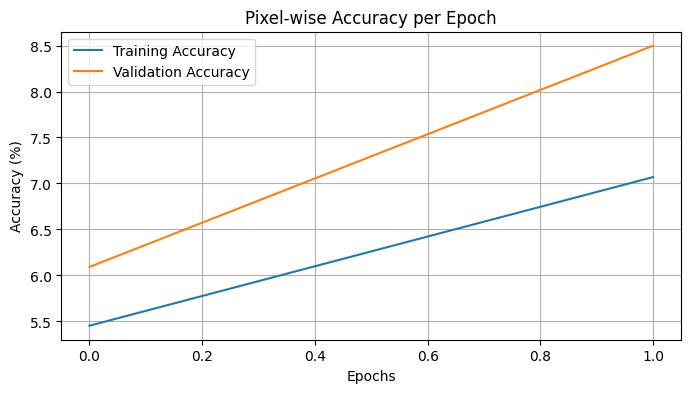

In [29]:
plt.figure(figsize=(8, 4))
plt.plot(tr_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Pixel-wise Accuracy per Epoch')
plt.ylabel('Accuracy (%)')
plt.xlabel('Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [30]:
import glob
import random
from PIL import Image
import numpy as np
from skimage.color import rgb2lab, lab2rgb
import torch
import os

import matplotlib.pyplot as plt

# 选取10张图片
# indices = random.sample(range(len(valdataset)), 10)

In [31]:
# results = []

# for idx in indices:
#     # —— 1) 从 valdataset 取出来的 L_input/ab —— 
#     L_input, ab_tensor = valdataset[idx]      # L_input:(1,H,W) 实际是 L−50
#     H, W = L_input.shape[1:]

#     # —— 2) 把 L_input + 50 → 还原成 [0,100] 范围 —— 
#     L_rs = (L_input.squeeze(0).cpu().numpy() + 50.0).astype(np.float32)  # (H,W)
#     ab_rs = ab_tensor.permute(1,2,0).cpu().numpy()                      # (H,W,2)

#     # —— 3) GT Lab → RGB —— 
#     lab_gt = np.concatenate([L_rs[:,:,None], ab_rs], axis=-1)           # (H,W,3)
#     img_gt = (np.clip(lab2rgb(lab_gt), 0,1)*255).astype(np.uint8)

#     # —— 4) 灰度图 —— 
#     grey = (L_rs/100.0*255).astype(np.uint8)
#     grey = np.stack([grey]*3, axis=-1)                                  # (H,W,3)

#     # —— 5) 推理得到 Pred ab —— 
#     L_in = (L_rs - 50.0)[None,None]                                     # (1,1,H,W)
#     L_in = torch.from_numpy(L_in).to(device)
#     with torch.no_grad():
#         logits    = net(L_in)                                           # (1,313,h',w')
#         logits_up = F.interpolate(
#             logits, size=(H,W), mode="bilinear", align_corners=False
#         )
#         idx_pred = logits_up.argmax(1).squeeze(0).cpu().numpy()        # (H,W)
#     ab_pred = ab_bins_cpu[idx_pred]                                    # (H,W,2)

#     # —— 6) Pred Lab → RGB —— 
#     lab_pr = np.concatenate([L_rs[:,:,None], ab_pred], axis=-1)
#     img_pr = (np.clip(lab2rgb(lab_pr),0,1)*255).astype(np.uint8)

#     # 6) 收集结果
#     results.append({
#         "gt":    img_gt,
#         "grey":  grey,
#         "pred":  img_pr,
#         "idx":   idx
#     })
# fig, axes = plt.subplots(10, 3, figsize=(6, 20))
# for i, r in enumerate(results):
#     axes[i,0].imshow(r["gt"])
#     axes[i,0].set_title(f"GT idx={r['idx']}")
#     axes[i,1].imshow(r["grey"], cmap='gray')
#     axes[i,1].set_title("Grey")
#     axes[i,2].imshow(r["pred"])
#     axes[i,2].set_title("Pred")
#     for ax in axes[i]:
#         ax.axis('off')
# plt.tight_layout()
# plt.show()


In [32]:
# import os
# import random
# import numpy as np
# import torch
# import torch.nn.functional as F
# import matplotlib.pyplot as plt
# from PIL import Image
# from skimage.color import rgb2lab, lab2rgb
# # size = (112, 112)  # resize to size

# net.eval()
# device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# image_dir   = r"C:\Users\Ting Ting\XIA\DATA\content\coco_dataset\test2014"
# ab_bins_cpu = ab_bins.cpu().numpy()
# Q = ab_bins.shape[0]

# indices = random.sample(range(len(val_prefixes)), 10)
# fig, axes = plt.subplots(len(indices), 3, figsize=(6, 2*len(indices)))

# for row, idx in enumerate(indices):
#     prefix = val_prefixes[idx]
#     jpg_p  = os.path.join(image_dir, prefix)

#     # —GT—
#     img = Image.open(jpg_p).convert("RGB").resize(size, Image.BILINEAR)
#     gt  = np.array(img)

#     # —Grey—
#     grey = np.array(img.convert("L"))
#     grey = np.stack([grey]*3, axis=-1)

#     # —Prepare L_in—
#     img_f  = np.array(img).astype(np.float32)/255.0
#     lab_np = rgb2lab(img_f)                          # NumPy: (64,64,3)
#     L_chan = lab_np[:,:,0:1]                         # NumPy: (64,64,1)
#     L_in   = (L_chan - 50.0)[None].transpose(0,3,1,2) # NumPy: (1,1,64,64)
#     L_in   = torch.from_numpy(L_in).to(device)

#     # —Forward + Annealed-mean—
#     with torch.no_grad():
#         logits    = net(L_in)                        # Torch: (1,Q,h',w')
#         logits_up = F.interpolate(
#             logits, size=size, mode="bilinear", align_corners=False
#         )                                             # (1,Q,64,64)

#         T     = 0.38
#         probs = F.softmax(logits_up, dim=1)           # (1,Q,64,64)
#         log_p = (probs + 1e-12).log() / T
#         fT    = F.softmax(log_p, dim=1)               # (1,Q,64,64)

#         # tensordot over Q dimension -> (1,64,64,2)
#         ab_mean = torch.tensordot(fT, ab_bins.to(device), dims=([1],[0]))
#         ab_mean = ab_mean.squeeze(0).cpu().numpy()    # (64,64,2)

#     # —Compose Pred Lab→RGB—
#     lab_pr = np.concatenate([L_chan, ab_mean], axis=-1)     # (64,64,3)
#     pr     = (np.clip(lab2rgb(lab_pr), 0,1)*255).astype(np.uint8)

#     # —Plot—
#     axes[row,0].imshow(gt);   axes[row,0].set_title(f"GT idx={idx}")
#     axes[row,1].imshow(grey); axes[row,1].set_title("Grey")
#     axes[row,2].imshow(pr);   axes[row,2].set_title("Pred")
#     for ax in axes[row]:
#         ax.axis("off")

# plt.tight_layout()
# plt.show()


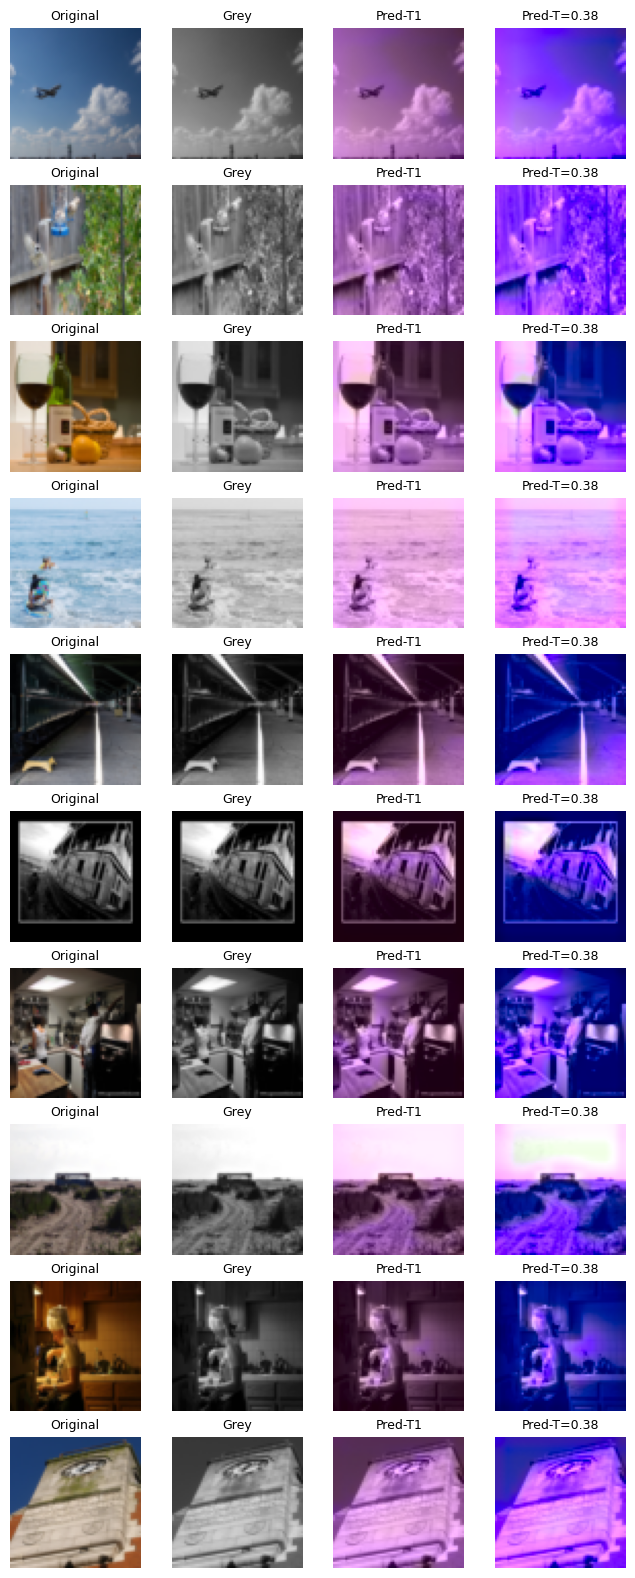

In [33]:
import os, random, numpy as np, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from skimage.color import rgb2lab, lab2rgb

net.eval()
device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_dir   = r"C:\Users\Ting Ting\XIA\DATA\content\coco_dataset\test2014"
ab_bins_cpu = ab_bins.cpu().numpy()
indices     = random.sample(range(len(val_prefixes)), 10)

fig, axes = plt.subplots(len(indices), 4, figsize=(8, 2*len(indices)))
results = []

T = 0.38                                       # annealing temperature
for row, idx in enumerate(indices):
    # -------- same I/O preparation as before --------
    prefix  = val_prefixes[idx]
    jpg_p   = os.path.join(image_dir, prefix)
    img_pil = Image.open(jpg_p).convert("RGB").resize(size, Image.BILINEAR)
    gt      = np.asarray(img_pil)
    grey3   = np.stack([np.asarray(img_pil.convert("L"))]*3, -1)

    lab_f   = rgb2lab(gt.astype(np.float32)/255.)
    L_chan  = lab_f[:,:,0:1]
    L_in    = torch.from_numpy((L_chan-50).transpose(2,0,1)[None]).to(device)

    with torch.no_grad():
        logits     = net(L_in)                                              # (1,Q,h',w')
        logits_up  = F.interpolate(logits, size=size,
                                   mode="bilinear", align_corners=False)    # (1,Q,H,W)

        # ---- (a)  T = 1  ----
        prob_T1 = F.softmax(logits_up, dim=1)                               # (1,Q,H,W)
        ab_T1   = torch.tensordot(prob_T1, ab_bins.to(device), dims=([1],[0])).squeeze(0)

        # ---- (b)  T = 0.38  (数值稳定实现) ----
        log_p   = F.log_softmax(logits_up, dim=1)           # 先做 log_softmax
        prob_T  = F.softmax(log_p / T, dim=1)               # 再除温度重 softmax
        ab_T    = torch.tensordot(prob_T, ab_bins.to(device), dims=([1],[0])).squeeze(0)

    # ------ Lab→RGB ------
    def lab2img(L, ab):
        out = np.concatenate([L, ab.cpu().numpy()], -1)
        return (np.clip(lab2rgb(out), 0, 1)*255).astype(np.uint8)

    pr_T1 = lab2img(L_chan, ab_T1) 
    pr_T  = lab2img(L_chan, ab_T )

 # -------- 保存到列表 --------
    results.append({
        "idx"     : idx,       # 或 prefix
        "gt"      : gt,
        "grey"    : grey3,
        "pred_T1" : pr_T1,     # ← now present
        "pred_T"  : pr_T       # ← now present
    })

    # -------- 画图（可选）--------
    titles = ["Original", "Grey", "Pred-T1", "Pred-T=0.38"]
    imgs   = [gt, grey3, pr_T1, pr_T]
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(imgs[col]); ax.set_title(titles[col], fontsize=9); ax.axis("off")



In [34]:
print(results[0].keys())


dict_keys(['idx', 'gt', 'grey', 'pred_T1', 'pred_T'])


In [35]:
from skimage.metrics import structural_similarity as ssim
import pandas as pd, os, numpy as np

def ssimd(a: np.ndarray, b: np.ndarray) -> float:
    # SSIM in [-1,1]  →  SSIMD in [0,1]
    return (1 - ssim(a, b, channel_axis=-1, data_range=255)) / 2

rows = []
for res in results:
    rows.append({
        "idx"                : res["idx"],                          # 整型编号
        "D(gt, grey)"        : ssimd(res["gt"],   res["grey"]),
        "D(gt, pred-T1)"     : ssimd(res["gt"],   res["pred_T1"]),
        "D(gt, pred-0.38)"   : ssimd(res["gt"],   res["pred_T"]),
    })

df = pd.DataFrame(rows)
df.loc["MEAN"] = df.mean(numeric_only=True)   # 末行求平均
display(df)



,idx,"D(gt, grey)","D(gt, pred-T1)","D(gt, pred-0.38)"
0,1608.0,0.035236,0.058692,0.128237
1,2204.0,0.056500,0.094459,0.224257
2,332.0,0.075693,0.098106,0.214703
3,2658.0,0.027737,0.044201,0.127653
4,2667.0,0.007367,0.065818,0.220880
5,317.0,0.000000,0.072938,0.170669
6,2206.0,0.008821,0.064806,0.179705
7,126.0,0.006305,0.032858,0.161973
8,2750.0,0.147375,0.153415,0.275126
9,1823.0,0.033488,0.056324,0.178113
